# IT3212 Assignment 1 - Student Graduation Dataset

## 1a. Data exploration

In [1]:
import pandas as pd

df = pd.read_csv("../data/graduation_dataset.csv")

display(df.head())
display(df.describe(include="all"))
display(df.dtypes)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nationality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nationality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graduate
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2209
mean,1.178571,6.886980,1.727848,9.899186,0.890823,2.531420,1.254521,12.322107,16.455244,7.317812,...,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969,NaN
std,0.605747,5.298964,1.313793,4.331792,0.311897,3.963707,1.748447,9.026251,11.044800,3.997828,...,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935,NaN
min,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000,NaN
25%,1.000000,1.000000,1.000000,6.000000,1.000000,1.000000,1.000000,2.000000,3.000000,5.000000,...,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000,NaN
50%,1.000000,8.000000,1.000000,10.000000,1.000000,1.000000,1.000000,13.000000,14.000000,6.000000,...,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000,NaN
75%,1.000000,12.000000,2.000000,13.000000,1.000000,1.000000,1.000000,22.000000,27.000000,10.000000,...,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000,NaN


Marital status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance                          int64
Previous qualification                              int64
Nationality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                             int64
Gender                                              int64
Scholarship holder                                  int64
Age at enrollm

### Target class distribution
The counts and percentages show whether the outcome classes are balanced. This motivates using a stratified train/test split.

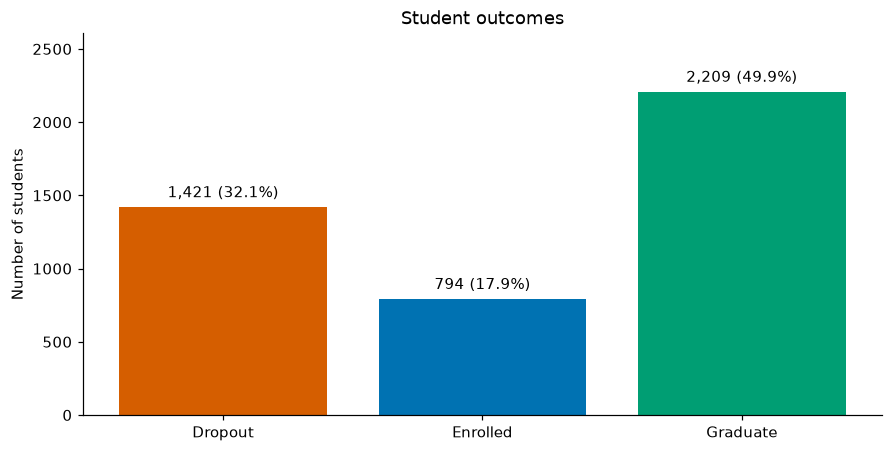

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from textwrap import fill

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12})
class_order = ["Dropout", "Enrolled", "Graduate"]
class_colors = ["#D55E00", "#0072B2", "#009E73"]

def short_label(column):
    return column.replace("Curricular units 1st sem", "Semester 1").replace(
        "Curricular units 2nd sem", "Semester 2")

counts = df["Target"].value_counts().reindex(class_order, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
bars = ax.bar(counts.index, counts.values, color=class_colors)
ax.bar_label(bars, labels=[f"{n:,} ({n / len(df):.1%})" for n in counts], padding=4)
ax.set(title="Student outcomes", ylabel="Number of students", ylim=(0, counts.max() * 1.18))
plt.show()

## 1b. Missing values, categorical values and outliers

In [3]:
# Missing values in each column
display(df.isna().sum())

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Nationality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrollment                                 0
International                                     0
Curricular u

In [4]:
# These columns contain categories, even though most are stored as numbers
categorical_columns = [
    "Marital status", "Application mode", "Course",
    "Daytime/evening attendance", "Previous qualification",
    "Nationality", "Mother's qualification",
    "Father's qualification", "Mother's occupation",
    "Father's occupation", "Displaced",
    "Educational special needs", "Debtor",
    "Tuition fees up to date", "Gender",
    "Scholarship holder", "International", "Target"
]

for column in categorical_columns:
    values = sorted(df[column].unique().tolist())
    print(f"{column}: {values}")

Marital status: [1, 2, 3, 4, 5, 6]
Application mode: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
Course: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
Daytime/evening attendance: [0, 1]
Previous qualification: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
Nationality: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
Mother's qualification: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
Father's qualification: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]
Mother's occupation: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]
Father's occupation: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 4

## 2. Handling missing values

The dataset contains no missing values. Therefore, no imputation or removal is needed, and all 4,424 rows are retained. Zero values are not treated as missing because they may be valid observations.

## 3a. Detecting outliers with the IQR method

Values below $Q1 - 1.5 \times IQR$ or above $Q3 + 1.5 \times IQR$ are identified as potential outliers. IQR was chosen because several numerical variables are skewed and contain many zero values. Unlike Z-score, IQR does not assume an approximately normal distribution and is less affected by extreme values.

In [5]:
# Detect outliers in numerical columns using the IQR method
numerical_columns = [
    column for column in df.columns if column not in categorical_columns
]

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = (df[numerical_columns] < lower_bound) | (df[numerical_columns] > upper_bound)

outlier_summary = pd.DataFrame({
    "Lower bound": lower_bound,
    "Upper bound": upper_bound,
    "Number of outliers": outliers.sum()
})

display(outlier_summary[outlier_summary["Number of outliers"] > 0])

,Lower bound,Upper bound,Number of outliers
Application order,-0.500,3.500000,541
Age at enrollment,10.000,34.000000,441
Curricular units 1st sem (credited),0.000,0.000000,577
Curricular units 1st sem (enrolled),2.000,10.000000,424
Curricular units 1st sem (evaluations),0.000,16.000000,158
Curricular units 1st sem (approved),-1.500,10.500000,180
Curricular units 1st sem (grade),7.400,17.000000,726
Curricular units 1st sem (without evaluations),0.000,0.000000,294
Curricular units 2nd sem (credited),0.000,0.000000,530
Curricular units 2nd sem (enrolled),2.000,10.000000,369


### Visual inspection of potential outliers
Each numerical feature has its own box plot and scale. The box spans the middle 50% of observations; the line marks the median. Whiskers reach the most distant observations within 1.5 ? IQR of the box, and points outside are potential outliers. The percentage chart summarises the same IQR rule across all numerical features.

These flags are prompts for inspection, not automatic reasons to remove students. For zero-heavy or discrete features, IQR can be zero, so even ordinary non-zero values can be flagged.

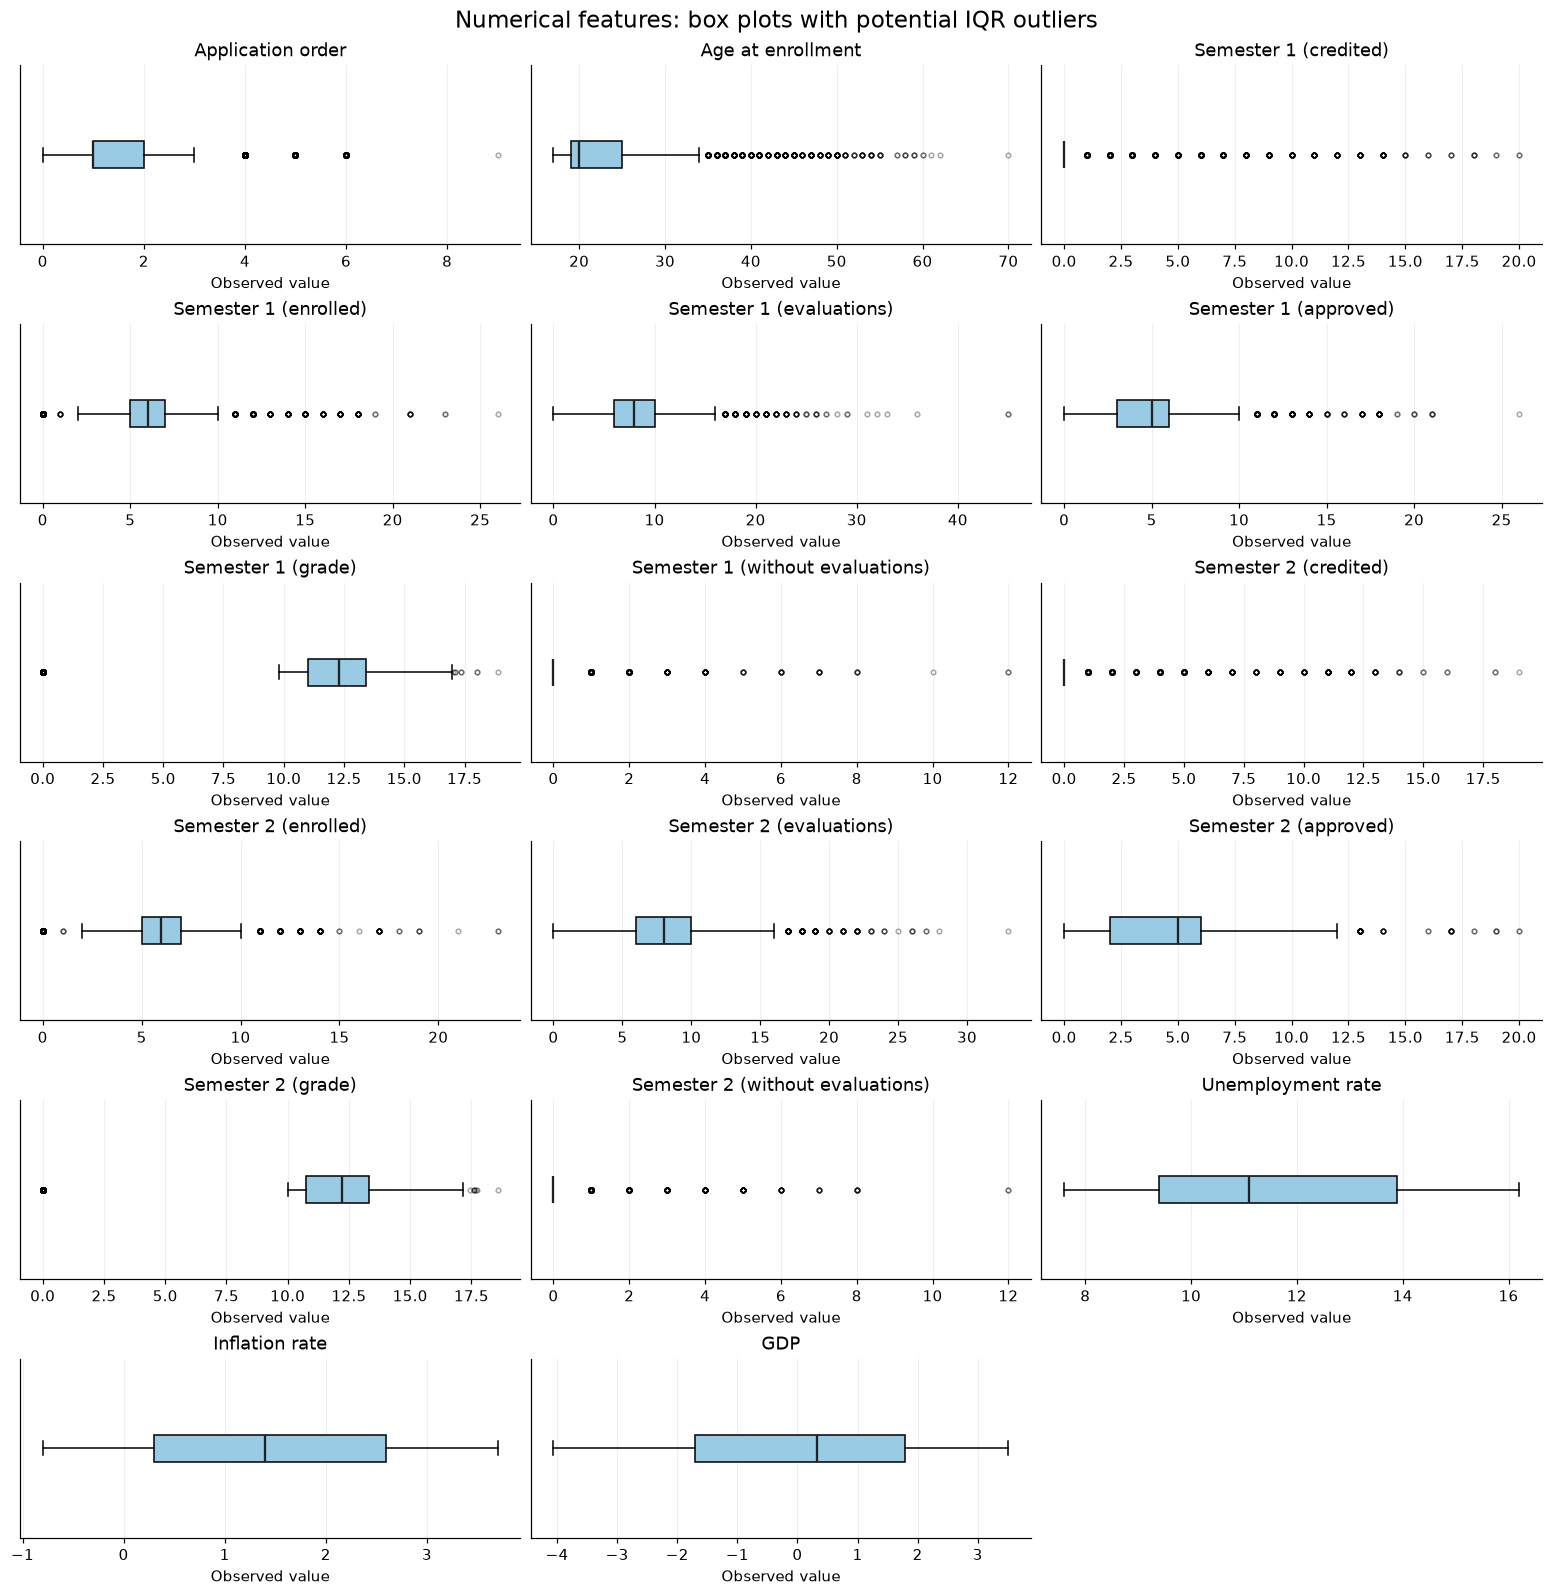

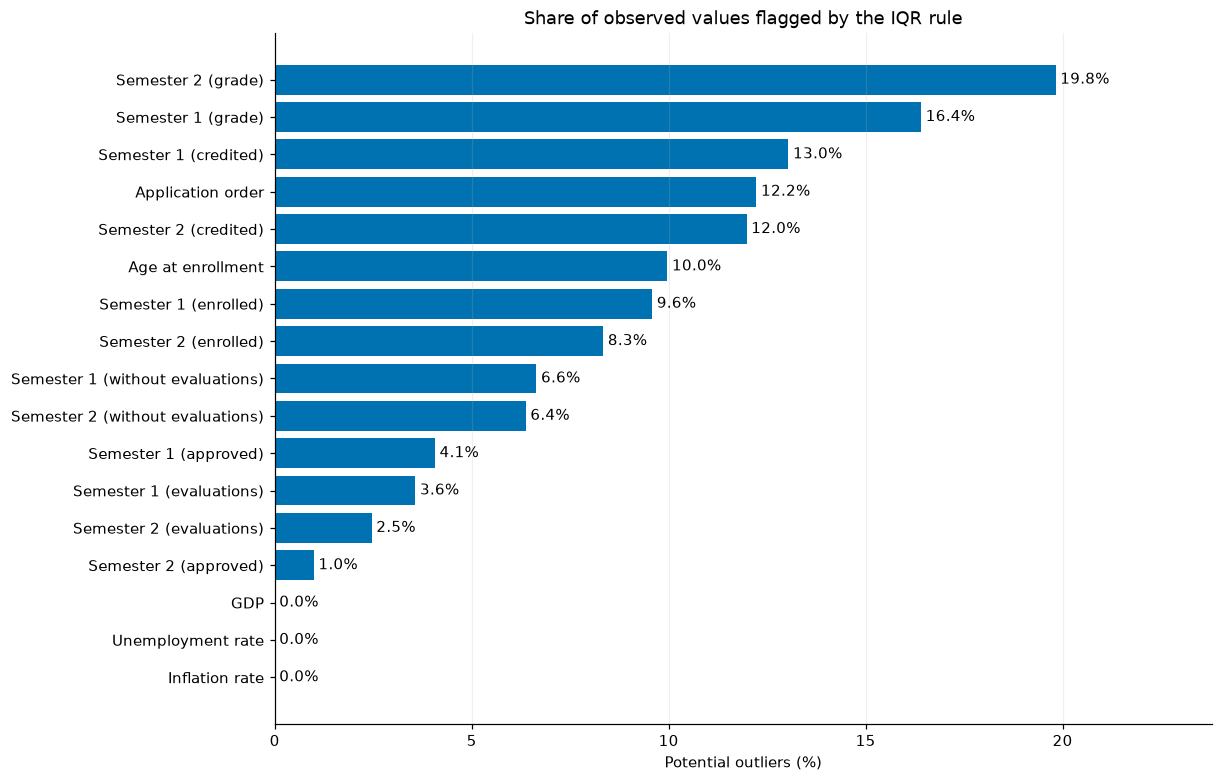

In [6]:
from math import ceil

fig, axes = plt.subplots(ceil(len(numerical_columns) / 3), 3,
                         figsize=(14, 2.4 * ceil(len(numerical_columns) / 3)),
                         layout="constrained")
for ax, column in zip(axes.flat, numerical_columns):
    ax.boxplot(df[column].dropna(), orientation="horizontal", whis=1.5, patch_artist=True,
               boxprops={"facecolor": "#99CBE4"},
               medianprops={"color": "#222222", "linewidth": 1.5},
               flierprops={"marker": "o", "markersize": 3, "alpha": 0.35})
    ax.set(title=fill(short_label(column), 34), xlabel="Observed value", yticks=[])
    ax.grid(axis="x", alpha=0.2)
for ax in list(axes.flat)[len(numerical_columns):]:
    ax.set_visible(False)
fig.suptitle("Numerical features: box plots with potential IQR outliers", fontsize=15)
plt.show()

outlier_percent = (outliers.sum() / df[numerical_columns].count() * 100).sort_values()
fig, ax = plt.subplots(figsize=(11, 7), layout="constrained")
bars = ax.barh([short_label(c) for c in outlier_percent.index], outlier_percent,
               color="#0072B2")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(title="Share of observed values flagged by the IQR rule",
       xlabel="Potential outliers (%)", xlim=(0, max(5, outlier_percent.max() * 1.2)))
ax.grid(axis="x", alpha=0.2)
plt.show()

### Selected box plots for the report

Box plots of all 17 numerical variables are shown above. The report uses three examples to illustrate different reasons for IQR flags: older students, zero grades and a zero-heavy credited-unit variable. The same 1.5 x IQR rule is used in every panel; each panel has its own scale. Potential outliers are not automatically recording errors.

The next cell saves a high-resolution PNG in `figures/` for use in Overleaf.

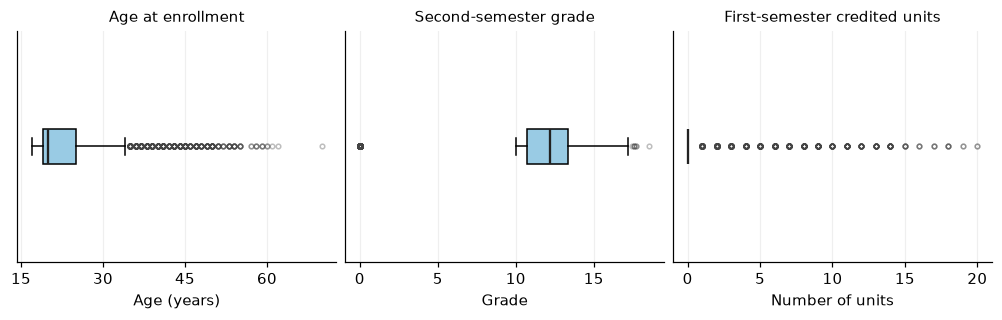

Saved report figure: C:\Users\ellin\OneDrive\Skrivebord\Skole\Data Powered Software\IT3212-assignment1\figures\student_outliers_selected.png


In [7]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

report_features = [
    ("Age at enrollment", "Age at enrollment", "Age (years)"),
    ("Curricular units 2nd sem (grade)", "Second-semester grade", "Grade"),
    ("Curricular units 1st sem (credited)", "First-semester credited units", "Number of units"),
]

# Use the repository figures folder when run from the root or notebooks/.
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
figure_dir = project_root / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_dir / "student_outliers_selected.png"

with plt.rc_context({"font.size": 10, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 3, figsize=(9, 2.8), layout="constrained")
    for ax, (column, title, xlabel) in zip(axes, report_features):
        ax.boxplot(
            df[column].dropna(), orientation="horizontal", whis=1.5,
            patch_artist=True,
            boxprops={"facecolor": "#99CBE4"},
            medianprops={"color": "#222222", "linewidth": 1.5},
            flierprops={"marker": "o", "markersize": 3,
                        "markeredgecolor": "#444444", "alpha": 0.35},
        )
        ax.set(title=title, xlabel=xlabel, yticks=[])
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
        ax.grid(axis="x", alpha=0.2)
    fig.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print(f"Saved report figure: {figure_path}")

### Correlation between numerical features
Pearson correlation highlights linear relationships and potentially redundant features, which can help motivate PCA. Category codes and the target are excluded because their numeric labels do not represent quantities. Correlation does not establish causation.

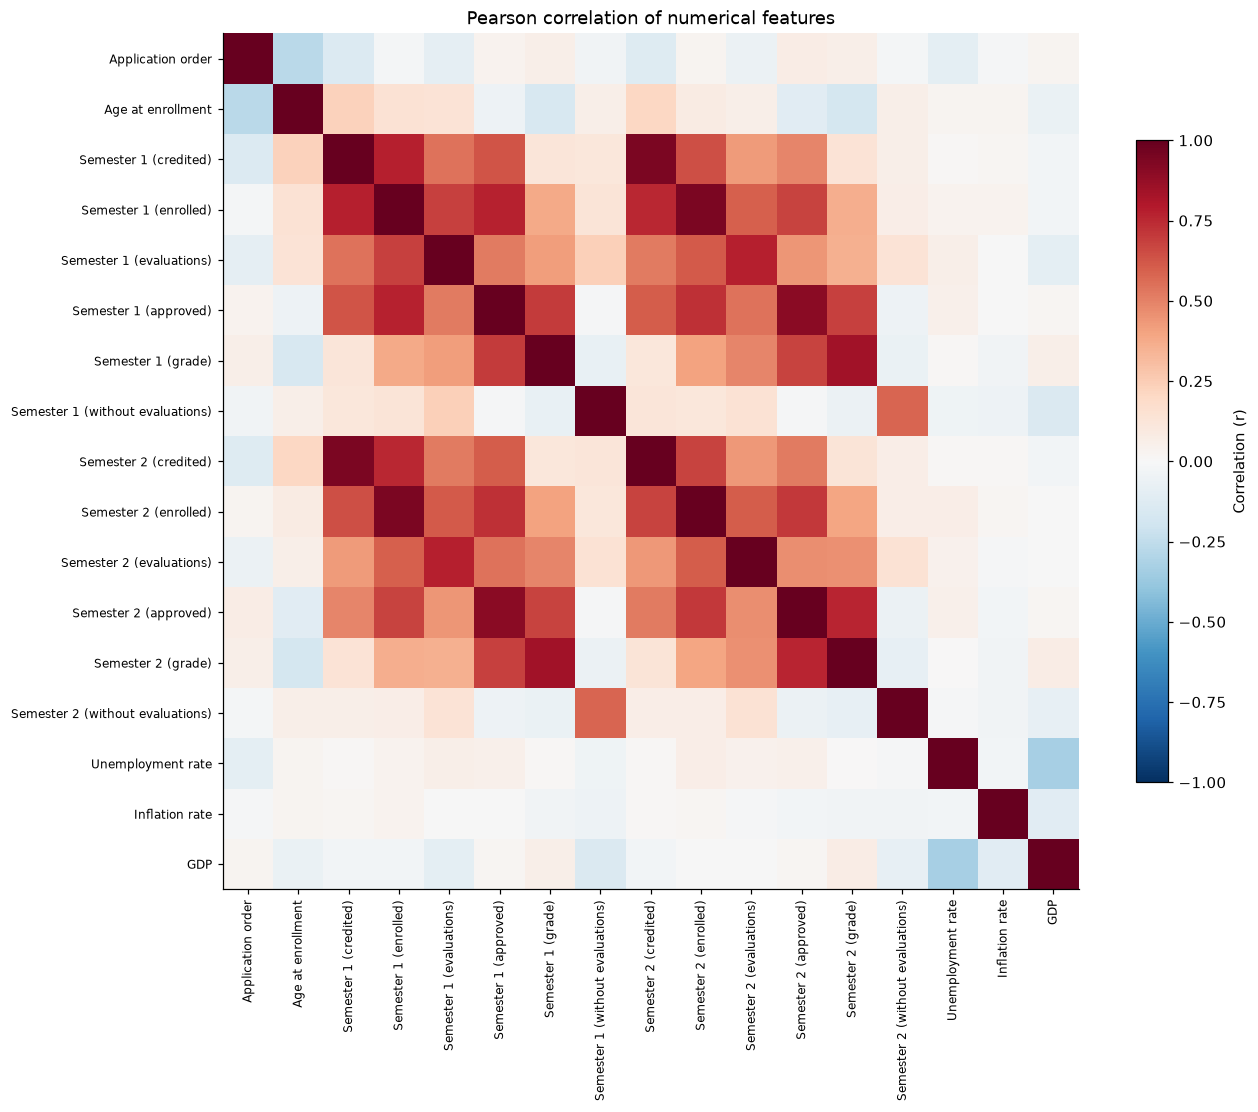

In [8]:
correlation = df[numerical_columns].corr()
labels = [short_label(c) for c in numerical_columns]
fig, ax = plt.subplots(figsize=(12, 10), layout="constrained")
heatmap = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
ax.set_title("Pearson correlation of numerical features")
fig.colorbar(heatmap, ax=ax, label="Correlation (r)", shrink=0.75)
fig.savefig(figure_dir / "student_correlation_matrix.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 3b. Handling outliers

All observations are retained. The extreme ages and curricular-unit values inspected above do not establish recording errors, so rows are not removed or capped. Retaining an observation does not rule out transforming its features.

Curricular-unit count variables with training-set skewness greater than 2 receive `log1p`. This practical threshold identifies strong positive skewness; it is not an optimized cutoff. Grades, age, economic variables and category codes are excluded from this selection. The transformation compresses high counts and preserves zeros, but does not prove that observations are correct or that predictive performance improves. It also does not resolve zero IQR in zero-heavy features.

The code runs below, after encoding and the train/test split, so the choice of transformed columns uses training data only. Original values remain in `df`, `X_train` and `X_test`.

## 4a. Encoding categorical data

Categorical features with more than two categories are one-hot encoded because their numerical codes represent labels, not quantities or order. Binary features are already represented by 0 and 1 and are kept unchanged. The target is label encoded because classification models require numerical class labels.

In [9]:
X = df.drop(columns="Target")
y = df["Target"].map({"Dropout": 0, "Enrolled": 1, "Graduate": 2})

categorical_features = [
    column for column in categorical_columns if column != "Target"
]
columns_to_encode = [
    column for column in categorical_features if df[column].nunique() > 2
]

X_encoded = pd.get_dummies(X, columns=columns_to_encode, dtype=int)

print("Encoded feature shape:", X_encoded.shape)
display(X_encoded.head())
display(y.head())

Encoded feature shape: (4424, 245)


,Application order,Daytime/evening attendance,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,...,Father's occupation_37,Father's occupation_38,Father's occupation_39,Father's occupation_40,Father's occupation_41,Father's occupation_42,Father's occupation_43,Father's occupation_44,Father's occupation_45,Father's occupation_46
0,5,1,1,0,0,1,1,0,20,0,...,0,0,0,0,0,0,0,0,0,0
1,1,1,1,0,0,0,1,0,19,0,...,0,0,0,0,0,0,0,0,0,0
2,5,1,1,0,0,0,1,0,19,0,...,0,0,0,0,0,0,0,0,0,0
3,2,1,1,0,0,1,0,0,20,0,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,1,0,0,45,0,...,0,0,0,0,0,0,0,0,0,0


0    0
1    2
2    0
3    2
4    2
Name: Target, dtype: int64

## 4b. Feature transformation and scaling

The split is performed before selecting log-transformed features or fitting StandardScaler. Selected count variables are transformed identically in training and test data. The 17 numerical features are then standardized using training means and standard deviations; binary and one-hot features remain unchanged. PCA uses this transformed and scaled representation.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

### Log1p for strongly right-skewed counts

Select columns using only training-set skewness. The table reports all count variables, including those left unchanged. The chart compares skewness before and after transformation on training data. The same selected columns receive log1p in the test set; no threshold is selected again using test data.

In [11]:
SKEWNESS_THRESHOLD = 2.0
count_columns = [
    column for column in numerical_columns
    if column.startswith("Curricular units ") and not column.endswith("(grade)")
]
train_skewness = X_train[count_columns].skew()
log_columns = train_skewness.index[train_skewness > SKEWNESS_THRESHOLD].tolist()

X_train_transformed = X_train.copy()
X_test_transformed = X_test.copy()
for column in log_columns:
    if (X_train[column] < 0).any() or (X_test[column] < 0).any():
        raise ValueError(f"Expected non-negative counts in {column}")
    X_train_transformed[column] = np.log1p(X_train[column].astype(float))
    X_test_transformed[column] = np.log1p(X_test[column].astype(float))

skewness_summary = pd.DataFrame({
    "Training skewness before": train_skewness,
    "Training skewness after": X_train_transformed[count_columns].skew(),
    "Applied log1p": [column in log_columns for column in count_columns],
})
display(skewness_summary.round(3))
print(f"Log1p applied to {len(log_columns)} count variables:")
for column in log_columns:
    print(f"- {column}")

# Original records, non-selected features and train/test membership are preserved.
unchanged_columns = [column for column in X_train if column not in log_columns]
pd.testing.assert_frame_equal(X_train_transformed[unchanged_columns], X_train[unchanged_columns])
pd.testing.assert_frame_equal(X_test_transformed[unchanged_columns], X_test[unchanged_columns])
for original, transformed in [(X_train, X_train_transformed), (X_test, X_test_transformed)]:
    assert original.index.equals(transformed.index)
    assert np.isfinite(transformed.to_numpy(dtype=float)).all()
    assert np.allclose(np.expm1(transformed[log_columns]), original[log_columns])
    assert (transformed[log_columns].eq(0) == original[log_columns].eq(0)).all().all()


,Training skewness before,Training skewness after,Applied log1p
Curricular units 1st sem (credited),4.203,2.763,True
Curricular units 1st sem (enrolled),1.650,1.650,False
Curricular units 1st sem (evaluations),0.901,0.901,False
Curricular units 1st sem (approved),0.775,0.775,False
Curricular units 1st sem (without evaluations),7.600,4.401,True
Curricular units 2nd sem (credited),4.678,2.987,True
Curricular units 2nd sem (enrolled),0.853,0.853,False
Curricular units 2nd sem (evaluations),0.349,0.349,False
Curricular units 2nd sem (approved),0.327,0.327,False
Curricular units 2nd sem (without evaluations),7.690,4.787,True


Log1p applied to 4 count variables:
- Curricular units 1st sem (credited)
- Curricular units 1st sem (without evaluations)
- Curricular units 2nd sem (credited)
- Curricular units 2nd sem (without evaluations)


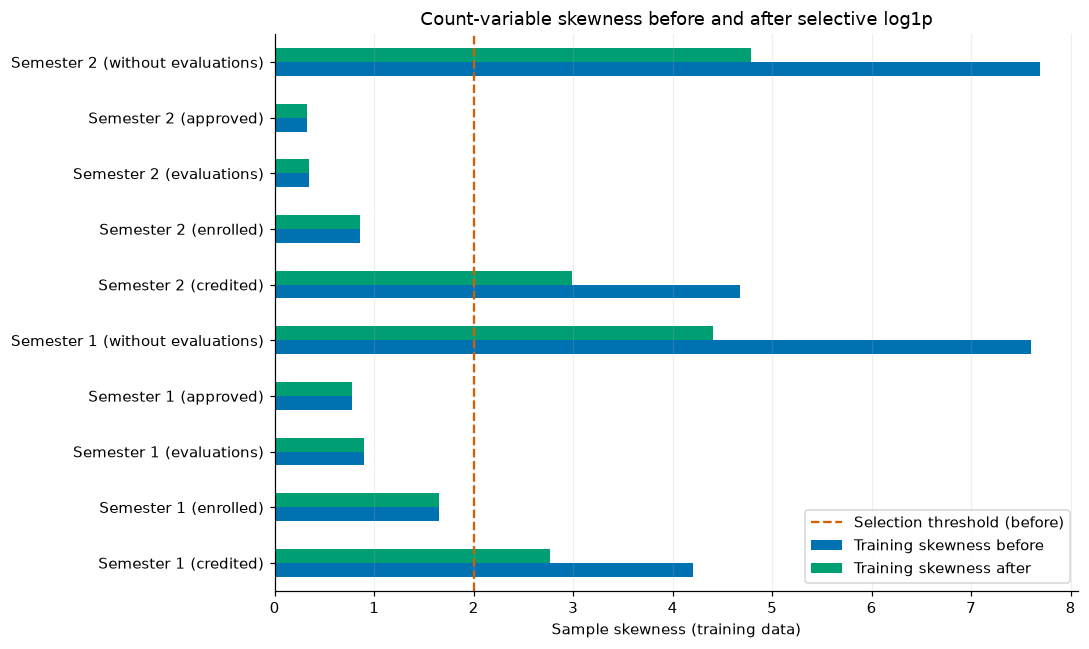

In [12]:
skewness_plot = skewness_summary.iloc[:, :2].copy()
skewness_plot.index = [short_label(column) for column in skewness_plot.index]
ax = skewness_plot.plot.barh(figsize=(10, 6), color=["#0072B2", "#009E73"])
ax.axvline(SKEWNESS_THRESHOLD, color="#D55E00", linestyle="--", label="Selection threshold (before)")
ax.set(title="Count-variable skewness before and after selective log1p",
       xlabel="Sample skewness (training data)", ylabel="")
ax.legend()
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.savefig(figure_dir / "student_log1p_skewness.png", dpi=300, bbox_inches="tight")
plt.show()


### Standardize the transformed numerical features

In [13]:
scaler = StandardScaler()
X_train_scaled = X_train_transformed.copy()
X_test_scaled = X_test_transformed.copy()

X_train_scaled[numerical_columns] = scaler.fit_transform(
    X_train_transformed[numerical_columns]
)
X_test_scaled[numerical_columns] = scaler.transform(
    X_test_transformed[numerical_columns]
)

display(X_train_scaled[numerical_columns].head())

,Application order,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
2283,-0.556229,-0.295828,3.425080,1.898375,1.363422,1.711901,0.364851,-0.252681,3.275485,1.700121,1.250659,1.838465,0.304781,-0.233753,0.872138,-1.103473,0.339595
3874,-0.556229,2.334335,-0.360537,-0.507336,-0.786079,-1.519082,-2.181071,2.246271,-0.343094,-0.552829,-0.765664,-1.464407,-1.949336,6.165182,0.421006,1.795972,-0.756629
2281,-0.556229,-0.295828,-0.360537,-0.106384,1.124589,-0.226689,0.231395,-0.252681,-0.343094,-0.102239,1.754739,-0.143258,0.056446,-0.233753,1.473648,1.143597,-1.795621
817,-0.556229,-0.690353,-0.360537,-0.106384,-0.547245,0.419507,0.796015,-0.252681,-0.343094,-0.102239,-0.513624,0.517316,0.502175,-0.233753,0.308223,-0.523584,0.779846
404,-0.556229,-0.558845,-0.360537,0.695519,-0.069578,0.742606,0.843531,-0.252681,-0.343094,0.798941,-0.009543,0.847603,0.864762,-0.233753,-0.293287,0.128791,0.757833


### Before and after standardization

This comparison starts after selective log1p. Numerical features have a training mean of zero and standard deviation one after standardization. Standardization itself preserves skewness; any log1p change has already taken place. Binary and one-hot features are unchanged.

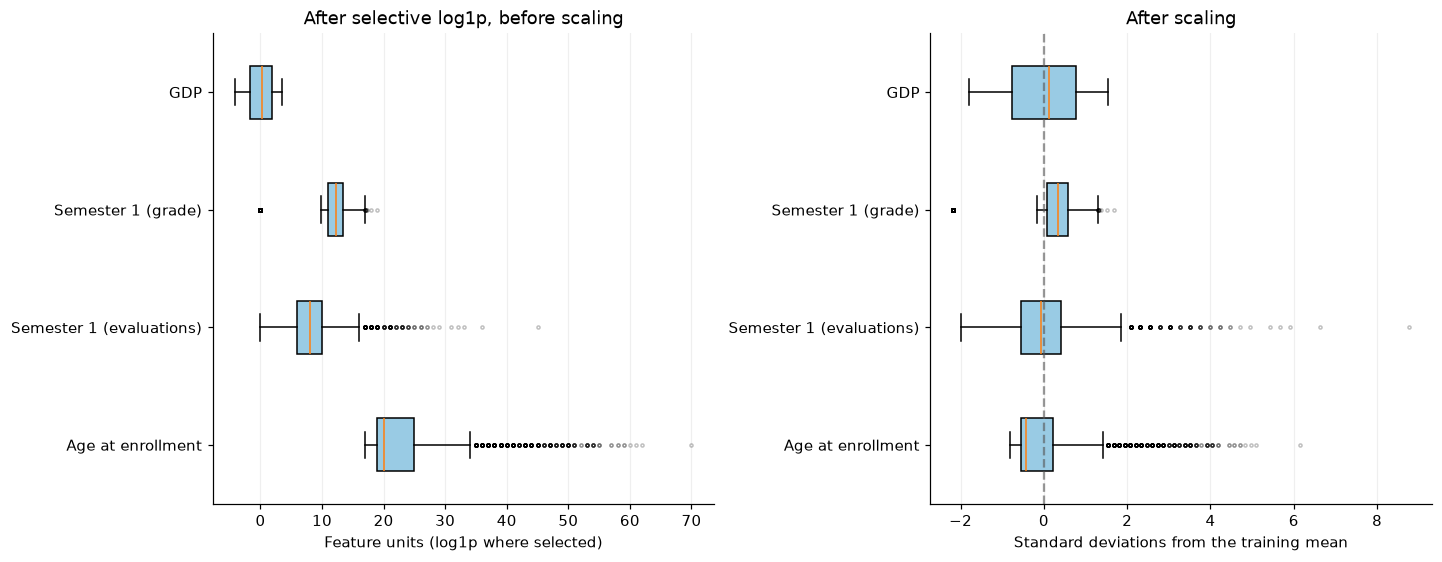

In [14]:
scaling_features = ["Age at enrollment", "Curricular units 1st sem (evaluations)",
                    "Curricular units 1st sem (grade)", "GDP"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, values, title, unit in zip(
    axes, [X_train_transformed, X_train_scaled], ["After selective log1p, before scaling", "After scaling"],
    ["Feature units (log1p where selected)", "Standard deviations from the training mean"]
):
    ax.boxplot([values[c].dropna() for c in scaling_features], orientation="horizontal",
               tick_labels=[short_label(c) for c in scaling_features], patch_artist=True,
               boxprops={"facecolor": "#99CBE4"},
               flierprops={"markersize": 2, "alpha": 0.25})
    ax.set(title=title, xlabel=unit)
    ax.grid(axis="x", alpha=0.2)
axes[1].axvline(0, color="#555555", linestyle="--", alpha=0.6)
plt.show()

## 5a. Training and testing split

The dataset is split into 80% training data and 20% testing data. Stratification keeps approximately the same distribution of target classes in both sets. A fixed random state makes the split reproducible.

In [15]:
print("Training rows:", len(X_train_scaled))
print("Testing rows:", len(X_test_scaled))

Training rows: 3539
Testing rows: 885


### Checking the stratified split
Compare percentages rather than raw counts because the training and test sets have different sizes. The bars should be nearly equal within each class.

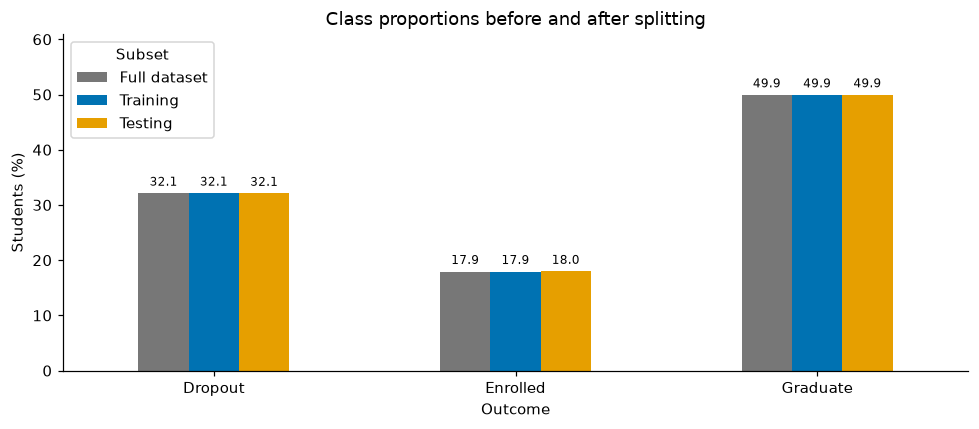

In [16]:
split_distribution = pd.DataFrame({
    "Full dataset": y.value_counts(normalize=True),
    "Training": y_train.value_counts(normalize=True),
    "Testing": y_test.value_counts(normalize=True)
}).reindex([0, 1, 2]).fillna(0) * 100
split_distribution.index = class_order
ax = split_distribution.plot.bar(figsize=(9, 4), rot=0,
                                  color=["#777777", "#0072B2", "#E69F00"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)
ax.set(title="Class proportions before and after splitting", ylabel="Students (%)",
       xlabel="Outcome", ylim=(0, split_distribution.max().max() * 1.22))
ax.legend(title="Subset")
plt.tight_layout()
plt.show()

## 5b. Importance of data splitting

The model learns from the training data, while the testing data is kept unseen for final evaluation. This gives a more realistic measure of how the model performs on new data and helps reveal overfitting. The split is also performed before fitting the scaler, preventing information from the testing data from leaking into the training process.

## 6. Principal Component Analysis (PCA)

PCA is applied to retain at least 80% of the training variance. This prioritizes a compact representation over the higher variance retention of a 95% threshold. The larger variance loss may discard predictive information; model performance must be evaluated separately. PCA is fitted only on training data and applied unchanged to test data.

In [17]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.80, svd_solver="full")
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train_scaled.shape[1])
print("Number of principal components:", pca.n_components_)
print("Explained variance:", pca.explained_variance_ratio_.sum().round(4))

Original number of features: 245
Number of principal components: 18
Explained variance: 0.8012


### How much variance is retained as components are added?
The left panel shows the variance explained by each component (a scree plot). The right panel adds those contributions to show cumulative explained variance, with 80%, 90%, 95% and 99% thresholds. A full PCA is fitted to the **training data only** to display the entire curve.

The horizontal axis counts **principal components**, not selected original features: each component is a weighted combination of input features. Explained variance describes the variation retained in the preprocessed inputs; it does not measure classification accuracy or guarantee that target-relevant information is preserved. The curve also depends on the scaling choice: numerical features are standardized here, while binary and one-hot features are not.

This curve uses selective log1p followed by standardization; results from the earlier untransformed analysis should not be reused.

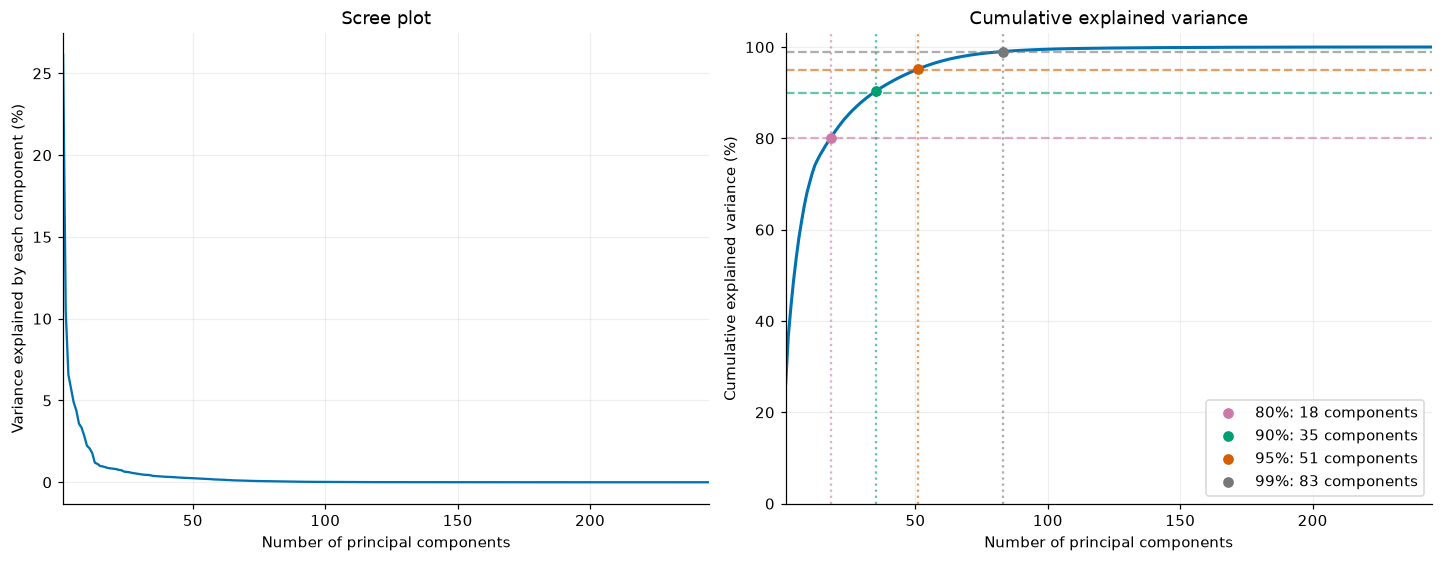

,Variance threshold (%),Components needed,Actual retained variance (%)
0,80,18,80.12
1,90,35,90.33
2,95,51,95.18
3,99,83,99.02


In [18]:
pca_full = PCA(svd_solver="full").fit(X_train_scaled)
variance_percent = pca_full.explained_variance_ratio_ * 100
cumulative_percent = np.cumsum(variance_percent)
component_counts = np.arange(1, len(variance_percent) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
axes[0].plot(component_counts, variance_percent, color="#0072B2", linewidth=1.5)
axes[0].set(title="Scree plot", xlabel="Number of principal components",
            ylabel="Variance explained by each component (%)")
axes[1].plot(component_counts, cumulative_percent, color="#0072B2", linewidth=2)
threshold_rows = []
for threshold, color in [(80, "#CC79A7"), (90, "#009E73"), (95, "#D55E00"), (99, "#777777")]:
    count = int(np.searchsorted(cumulative_percent, threshold) + 1)
    threshold_rows.append({"Variance threshold (%)": threshold, "Components needed": count,
                           "Actual retained variance (%)": cumulative_percent[count - 1]})
    axes[1].axhline(threshold, color=color, linestyle="--", alpha=0.6)
    axes[1].axvline(count, color=color, linestyle=":", alpha=0.6)
    axes[1].scatter(count, cumulative_percent[count - 1], color=color, zorder=3,
                    label=f"{threshold}%: {count} components")
axes[1].set(title="Cumulative explained variance", xlabel="Number of principal components",
            ylabel="Cumulative explained variance (%)", ylim=(0, 103))
axes[1].legend(loc="lower right")
for ax in axes:
    ax.set_xlim(1, len(component_counts))
    ax.grid(alpha=0.2)
fig.savefig(figure_dir / "student_pca_explained_variance.png", dpi=300, bbox_inches="tight")
plt.show()
display(pd.DataFrame(threshold_rows).round(2))

### Students projected onto the first two components
This training-data view shows how outcomes overlap in two dimensions. Class labels are used only for colouring and are not inputs to PCA. Read the variance percentages on the axes: two components capture only part of the variation, so overlap here does not establish how well a classifier can perform with all components.

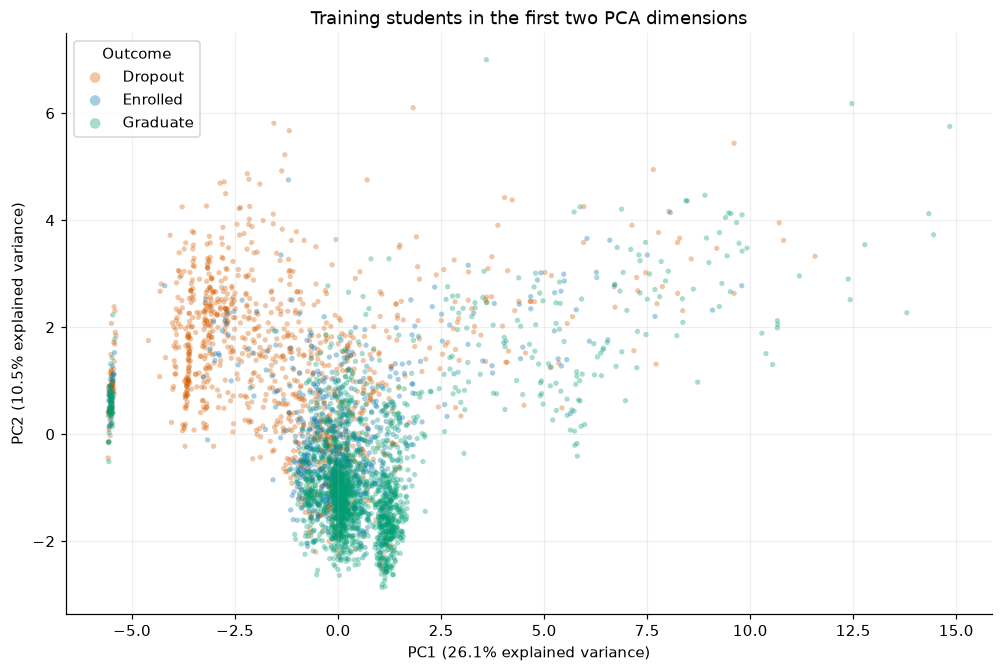

In [19]:
fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
for class_id, label, color in zip([0, 1, 2], class_order, class_colors):
    mask = y_train.to_numpy() == class_id
    ax.scatter(X_train_pca[mask, 0], X_train_pca[mask, 1],
               s=12, alpha=0.35, color=color, label=label, edgecolors="none")
ax.set(title="Training students in the first two PCA dimensions",
       xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} explained variance)",
       ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} explained variance)")
ax.legend(title="Outcome", markerscale=2)
ax.grid(alpha=0.2)
plt.show()

The output above reports the reduction from encoded input features to principal components and the retained variance for this run. PCA can reduce computation time and redundancy, but discards some variance and makes features harder to interpret. Whether it improves prediction must be evaluated by comparing models with and without PCA.